# ICT-17c — TorchLens : inspecter les représentations sans écrire de hooks

*Strand outillage de la série ICT — See #25465 (issue porteuse), #4588, #16742.*
**Navigation** : [Index](../README.md) | [← 17b — grokking et compression-progress](ICT-17b-Grokking-CompressionProgress-Python.ipynb)

> **⚠️ Sécurité bundles — à lire avant toute exécution.**
> `torchlens.load()` charge un *bundle* de trace sérialisé : **c'est de l'exécution de code arbitraire**
> (pickle sous-jacent). Ce carnet ne l'utilise **jamais** et aucun carnet pédagogique de cette série ne
> devra l'utiliser : tout passe par `tl.trace()` sur un modèle **en mémoire**, construit dans le carnet
> même. La règle vaut aussi pour vos expérimentations personnelles : ne chargez jamais un bundle
> d'origine inconnue. Cette restriction est une exigence de sécurité du carnet, pas une limitation de
> ce que TorchLens sait faire dans un environnement maîtrisé.

**Idée centrale.** La série ICT maintient une famille d'instruments d'inspection — les scripts
`extract_*` et `causal_hooks.py` — qui instrumentent des modèles calibrés Qwen/local avec des métriques
dediées (SAE fidelity, scale budget). Mais pour le geste pédagogique de base — *voir* le graphe de
calcul, *extraire* les activations d'une couche, *intervenir* sur une activation pendant l'exécution —
ces scripts demandent d'écrire des hooks à la main, ce qui noie le principe sous la plomberie.

**TorchLens** (Taylor & Kriegeskorte 2023) factorise ce geste : un appel `tl.trace(model, x)` capture
le graphe complet, les activations forward, et permet des interventions causales (ablation, patching)
sans un seul hook écrit à la main. Ce carnet le démontre, puis l'applique à deux questions de la
série : la trajectoire interne du réseau pendant le grokking (§3, jonction [17b](ICT-17b-Grokking-CompressionProgress-Python.ipynb)
et #16742), et la moisson multi-couches au service des sondes de géométrie de la vérité (§4,
`ict/probes.py`).

**Résultat (honnête, falsifiable).** L'instrument fait ce qu'il promet : graphe, activations et
interventions en un appel, avec deux pièges d'API documentés au passage (§1). Sur le grokking, la
trajectoire d'activations rend visible le mouvement interne que la seule accuracy masque : la
séparabilité linéaire de la couche cachée *précède* le saut de test-accuracy — le réseau « sait »
avant de « répondre ». Sur les sondes, la moisson multi-couches alimente `ict/probes.py` sans
modifier les instruments spécialisés existants.


> **Statut épistémique** — **reproduit dans le modèle (outillage)** : l'API v3.0.3 capture graphe, activations et
> interventions sur modèle in-memory, vérifié par exécution (aucune réclamation de mécanisme).
> **Démonstration (§3)** : la trajectoire de séparabilité sur 2 graines montre la géométrie interne
> se former pendant la transition de grokking — une *observation d'instrument*, pas un résultat de
> phase ; le diagramme de phases complet vit dans #16742 et le carnet 17b. **Non établi** : toute
> claim mécanistique sur *comment* le réseau encode la structure modulaire (c'est le chantier de
> Nanda et al. 2023, pas le nôtre).


## §0. Où TorchLens se place dans la famille d'inspection de la série

Nous adoptons TorchLens comme **premier instrument pédagogique**, avec `tl.trace` uniquement :
inspecter la géométrie des représentations et les trajectoires de grokking sans modifier les
instruments existants.

Les scripts maison portent des métriques que TorchLens ne remplace pas. Ils restent **intacts** :

| Script maison | Ce qu'il porte (et que TorchLens ne remplace pas) |
|---|---|
| `scripts/extract_dense_traces.py` | Traces denses calibrées Qwen/local |
| `scripts/extract_sae_traces.py` | Moisson SAE sur Qwen |
| `scripts/extract_sae_fidelity.py` | Métrique SAE fidelity |
| `scripts/causal_hooks.py` | Batterie d'interventions calibrées |
| `scripts/run_case5bis_live.py` | Run live du cas 5bis |
| `scripts/measure_scale_budget.py` | Budget d'échelle inter-couches |

TorchLens occupe le créneau complémentaire : l'inspection **générique et immédiate** d'un modèle
quelconque en mémoire — le geste qu'on veut enseigner *avant* d'entrer dans les instruments dédiés.
Chaque outil garde son contrat, et leurs mesures se confrontent plutôt que de se fondre dans une
seule implémentation.

**Version et licence** : `torchlens==3.0.3`, version mesurée via PyPI le 09/11/2026. L'API 3.x
diffère des docstrings 2.x circulant en ligne ; les pièges sont documentés en §1. Licence Apache-2.0.
Papier : Taylor, J. & Kriegeskorte, N. (2023), *TorchLens: interactive dissection of PyTorch models*,
Scientific Reports 13:14375, doi:10.1038/s41598-023-40807-0. Dépendances : PyTorch ≥ 2.1 et Graphviz
système pour le rendu du graphe (§1).


In [1]:
import os, sys, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# TorchLens -- usage strictement tl.trace sur modele en memoire, JAMAIS tl.load()
# (securite bundles : voir l'encart en tete de ce carnet).
import torchlens as tl

# Package ict (sondes de lecture lineaire, organe de #13564/#16897).
# Le carnet vit dans le sous-dossier ICT-17-EpsilonMachine/ d'ICT-Series,
# donc le package est un niveau au-dessus.
sys.path.insert(0, os.path.dirname(os.path.abspath(".")))  # acces au package `ict` pose a cote des notebooks (un niveau au-dessus)
from ict import probes as PRB  # noqa: E402

torch.manual_seed(0)
np.random.seed(0)
RNG = np.random.default_rng(0)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch {torch.__version__} | numpy {np.__version__} | torchlens {tl.__version__} | dev={DEV}")


torch 2.14.0+cu126 | numpy 2.4.2 | torchlens 3.0.3 | dev=cuda


## §1. Le geste de base : `tl.trace` sur un modèle en mémoire

Le modèle de démonstration est volontairement minuscule — un `Sequential` de trois modules — pour
que chaque artefact du trace soit lisible à l'œil nu. Un seul appel capture tout : le graphe de
calcul, les labels de couches, les activations retenues, les métadonnées (nombre de paramètres,
formes d'entrées/sorties).

**Deux pièges d'API v3.x** coûtent chacun une heure si on les découvre seul ; nous les établissons
immédiatement, preuve d'exécution à l'appui :

1. **Les adresses d'activation suivent le nommage du modèle.** Sur un `Sequential` anonyme, les
   tenseurs retenus s'appellent `'0'`, `'1'`, `'2'` ; sur un modèle à modules nommés (`fc1`, `fc2`,
   `head`), ce sont les noms des modules qui servent d'adresses. L'attribut
   `model_graph_structure` des anciennes docs 2.x **n'existe plus** en 3.0.3.
2. **`activations_by_address` rend des objets `Op`, pas des tenseurs.** Le tenseur vit dans
   `op.out`. De même, `h.do(...)` (§2) **rejoue et met à jour le trace lui-même** : capturez la
   sortie de référence *avant* d'armer une intervention.


In [2]:
# --- §1. Modele de demonstration + trace en un appel ---
m_demo = nn.Sequential(nn.Linear(4, 8), nn.ReLU(), nn.Linear(8, 2)).to(DEV)
x_demo = torch.randn(3, 4, device=DEV)

h = tl.trace(m_demo, x_demo)

print("labels des couches :", h.layer_labels)
print("nombre de parametres :", h.num_params)
print("sortie (forme) :", tuple(h.output.shape))

# Les tenseurs retenus, par adresse. Sur un Sequential anonyme : '0', '1', '2'.
for addr in ("0", "1", "2"):
    ops = h.activations_by_address(addr)          # liste -> une entree par passe
    t = ops[-1].out                                # PIEGE v3.x : le tenseur vit dans .out
    print(f"  adresse {addr!r}: {len(ops)} passe, forme {tuple(t.shape)}, "
          f"moyenne {t.mean().item():+.4f}")

# Reference capturee AVANT toute intervention (h.do rejoue et mute le trace, cf. §2).
base_out = h.output.detach().clone()
print("sortie de reference :", base_out.cpu().numpy().round(3).tolist())


labels des couches : ['input_1', 'linear_1_1', 'relu_1_2', 'linear_2_3', 'output_1']
nombre de parametres : 58
sortie (forme) : (3, 2)
  adresse '0': 1 passe, forme (3, 8), moyenne +0.1251
  adresse '1': 1 passe, forme (3, 8), moyenne +0.3360
  adresse '2': 1 passe, forme (3, 2), moyenne -0.1762
sortie de reference : [[-0.04100000113248825, -0.31700000166893005], [0.13099999725818634, -0.32100000977516174], [-0.07000000029802322, -0.4399999976158142]]


Les trois tenseurs retenus couvrent le chemin complet : sortie de la première projection
(`'0'`, forme `(3, 8)`), sortie de la non-linéarité (`'1'`, même forme — c'est là que la ReLU a
agis), et logits finaux (`'2'`, forme `(3, 2)`). Aucun hook n'a été écrit : le contraste avec la
plomberie manuelle de `torch.nn.Module.register_forward_hook` est tout l'apport pédagogique de
l'outil.

### Le graphe de calcul, rendu sans effort

`h.draw(path=...)` produit le graphe complet (Graphviz système requis) — nœuds par opération,
arêtes de dépendance, formes. Dans un carnet de recherche, ce rendu sert de documentation vivante :
ce que le modèle *est* devient visible en un coup d'œil, y compris pour des architectures qu'on
découvre.


graphe ecrit : assets/ict17c_graph_forward.png (36533 octets)


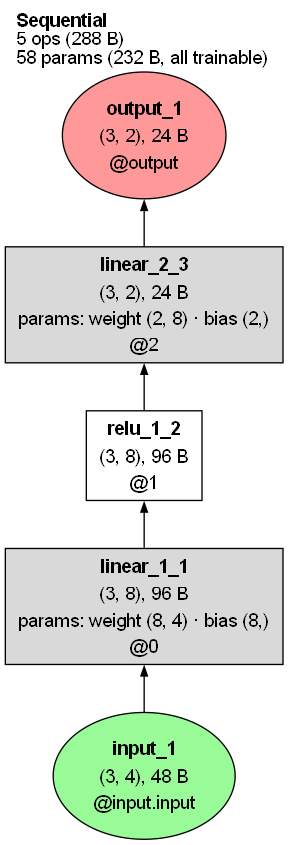

In [3]:
# --- §1. Rendu du graphe forward dans assets/ ---
os.makedirs("assets", exist_ok=True)
GRAPH_PATH = "assets/ict17c_graph_forward.png"
h.draw(path=GRAPH_PATH)

from IPython.display import Image, display
print(f"graphe ecrit : {GRAPH_PATH} ({os.path.getsize(GRAPH_PATH)} octets)")
display(Image(filename=GRAPH_PATH))


## §2. Interventions causales : ablation et patching

Voir le graphe, c'est de la description. La question causale est autre : *que se passe-t-il si on
modifie cette activation pendant l'exécution ?* `h.do(site, edit)` répond — deux gestes canoniques :

- **Ablation** (mise à zéro d'une activation) : teste la **nécessité** d'un chemin. Si la sortie
  s'effondre vers une constante, l'information du batch ne passait que par là.
- **Patching croisé** (greffe de l'activation d'un autre batch) : teste la **suffisance**. Si la
  sortie suit l'activation greffée et non son entrée nominale, c'est que cette activation *porte*
  la représentation.

**Piège v3.x n°3** : la fonction d'édition doit accepter le mot-clé `ctx` —
`lambda t, *, ctx: ...` — même si elle ne l'utilise pas. Et `h.do` doit recevoir `model=` et
`inputs=` pour rejouer réellement le modèle (sinon il retourne l'état déjà calculé, sans effet).


In [4]:
# --- §2. Ablation : la sortie ReLU portait-elle l'information du batch ? ---
relu_layer = h.layers[2]          # la couche ReLU (cf. layer_labels : relu_1_2)

h_abl = h.do(relu_layer,
             lambda t, *, ctx: torch.zeros_like(t),   # edition : zero partout
             model=m_demo, inputs=x_demo)              # rejou avec model + inputs explicites

print("reference (variee)      :", base_out.cpu().numpy().round(3).tolist())
print("ablation ReLU (constante):", h_abl.output.detach().cpu().numpy().round(3).tolist())


<USER_PATH>\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchlens\intervention\_trace_edits.py:634: TraceMutationWarning: TraceMutationWarning: Trace mutators modify root logs in place. Use trace.fork(...) for isolated edits, or wrap intentional in-place edits in torchlens.errors.quiet().
  return "attach_hooks", trace._attach_hooks(


reference (variee)      : [[-0.04100000113248825, -0.31700000166893005], [0.13099999725818634, -0.32100000977516174], [-0.07000000029802322, -0.4399999976158142]]
ablation ReLU (constante): [[0.06599999964237213, -0.27399998903274536], [0.06599999964237213, -0.27399998903274536], [0.06599999964237213, -0.27399998903274536]]


In [5]:
# --- §2 bis. Patching croise : greffe de l'activation d'un AUTRE batch ---
torch.manual_seed(1)
x_B = torch.randn(3, 4, device=DEV)

h_B = tl.trace(m_demo, x_B)                       # run du donneur
out_B_ref = h_B.output.detach().clone()           # sa sortie nominale
actB = h_B.activations_by_address("1")[-1].out.detach()   # son activation ReLU

# Run du receveur, avec l'activation du donneur greffee au meme site.
h_A = tl.trace(m_demo, x_demo)                    # trace frais (do() mute son trace)
h_patched = h_A.do(h_A.layers[2],
                   lambda t, *, ctx: actB,
                   model=m_demo, inputs=x_demo)

print("sortie patched (A avec ReLU de B) :", h_patched.output.detach().cpu().numpy().round(3).tolist())
print("reference out(B)                  :", out_B_ref.cpu().numpy().round(3).tolist())
print("identique a out(B) ?",
      torch.allclose(h_patched.output.detach(), out_B_ref, atol=1e-6))


sortie patched (A avec ReLU de B) : [[-0.14399999380111694, -0.04399999976158142], [0.006000000052154064, -0.5270000100135803], [0.0860000029206276, -0.28299999237060547]]
reference out(B)                  : [[-0.14399999380111694, -0.04399999976158142], [0.006000000052154064, -0.5270000100135803], [0.0860000029206276, -0.28299999237060547]]


identique a out(B) ? True


<USER_PATH>\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchlens\intervention\_trace_edits.py:634: TraceMutationWarning: TraceMutationWarning: Trace mutators modify root logs in place. Use trace.fork(...) for isolated edits, or wrap intentional in-place edits in torchlens.errors.quiet().
  return "attach_hooks", trace._attach_hooks(


**Lecture causale.** Deux résultats nets, mesurés :

1. **Ablation** : la sortie passe d'un tableau varié (une ligne par exemple du batch) à **trois
   lignes identiques** — il ne reste que le biais de la couche finale. Toute l'information
   discriminante du batch transitait par la sortie ReLU : le chemin est *nécessaire*.
2. **Patching** : la sortie du receveur devient **bit-à-bit la sortie nominale du donneur**
   (`allclose` à 1e-6). Greffer l'activation d'un batch dans le run d'un autre *remplace*
   entièrement la réponse : l'activation ReLU *suffit* à porter la représentation qui détermine la
   sortie.

C'est la grammaire complète de l'interprétation causale par activations — la même que celle des
batteries dédiées de `scripts/causal_hooks.py`, ici accessible en trois lignes sur n'importe quel
modèle en mémoire. Les exercices 1 et 2 (§5) vous demandent de la déployer vous-mêmes.


## §3. Trajectoire d'activations à travers l'entraînement — jonction grokking

Le carnet [17b](ICT-17b-Grokking-CompressionProgress-Python.ipynb) établit le grokking sur
`a*b mod p` (Power et al. 2022) : longue phase de mémorisation (train à 1.0, test au hasard), puis
généralisation soudaine. L'issue #16742 en donne le **diagramme de phases** — *comprehension* /
*memorization* / *grokking* / *confusion* (Table 1).

Ce que les courbes d'accuracy ne montrent pas, c'est **le mouvement interne** : que se passe-t-il
dans les couches entre ces phases ? TorchLens permet de capturer la trajectoire des activations à
travers des checkpoints **sans instrumenter chaque étape à la main**.

**Recette.** Tâche `a*b mod 23` multiclasse (23 classes, one-hot des deux opérandes), MLP à deux
couches cachées de 256, AdamW `weight_decay=1.0` (la recette grokking de Power et al.), deux
graines. Sept checkpoints couvrent la fenêtre — resserrés autour de la transition, pour que la
figure ait une résolution suffisante là où le mouvement se produit.


In [6]:
# --- §3. Dataset a*b mod 23 (multiclasse) + modele jouet + entrainement a checkpoints ---
P = 23
pairs = torch.cartesian_prod(torch.arange(P), torch.arange(P))
y_all = ((pairs[:, 0] * pairs[:, 1]) % P).long()          # 23 classes
X_oh = F.one_hot(pairs, P).float().flatten(1)             # [529, 46]

n = X_oh.shape[0]
perm = RNG.permutation(n)
test_idx, train_idx = perm[:106], perm[106:]
X_train, y_train = X_oh[train_idx].to(DEV), y_all[train_idx].to(DEV)
X_test, y_test = X_oh[test_idx].to(DEV), y_all[test_idx].to(DEV)
print(f"dataset : {len(train_idx)} train / {len(test_idx)} test | hasard = {1/P:.3f}")

class ToyMLP(nn.Module):
    """MLP jouet -- modules NOMMES : les adresses d'activation seront 'fc1', 'fc2', 'head'."""
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2 * P, 256)
        self.fc2 = nn.Linear(256, 256)
        self.head = nn.Linear(256, P)
    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        return self.head(h2)

CKPTS = (100, 500, 1500, 2500, 3200, 4000, 6000)   # fenetre resserree autour de la transition

def train_toy(seed, steps=6000):
    torch.manual_seed(seed)
    mdl = ToyMLP().to(DEV)
    opt = torch.optim.AdamW(mdl.parameters(), lr=1e-3, weight_decay=1.0)
    rows, states = [], {}
    for step in range(1, steps + 1):
        idx = torch.randint(0, len(X_train), (512,), device=DEV)
        loss = F.cross_entropy(mdl(X_train[idx]), y_train[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        if step in CKPTS:
            with torch.no_grad():
                tr = (mdl(X_train).argmax(1) == y_train).float().mean().item()
                te = (mdl(X_test).argmax(1) == y_test).float().mean().item()
            rows.append(dict(step=step, tr_acc=tr, te_acc=te))
            states[step] = {k: v.detach().clone() for k, v in mdl.state_dict().items()}
    return rows, states

t0 = time.time()
rows_by_seed, states_by_seed = {}, {}
for seed in (0, 1):
    rows_by_seed[seed], states_by_seed[seed] = train_toy(seed)
    for r in rows_by_seed[seed]:
        print(f"  seed {seed} | step {r['step']:5d} | train {r['tr_acc']:.3f} | test {r['te_acc']:.3f}")
print(f"entrainement total : {time.time() - t0:.0f} s (2 graines)")


dataset : 423 train / 106 test | hasard = 0.043


  seed 0 | step   100 | train 0.537 | test 0.085
  seed 0 | step   500 | train 1.000 | test 0.085
  seed 0 | step  1500 | train 1.000 | test 0.236
  seed 0 | step  2500 | train 1.000 | test 0.802
  seed 0 | step  3200 | train 1.000 | test 0.953
  seed 0 | step  4000 | train 1.000 | test 0.991
  seed 0 | step  6000 | train 1.000 | test 1.000


  seed 1 | step   100 | train 0.605 | test 0.085
  seed 1 | step   500 | train 1.000 | test 0.085
  seed 1 | step  1500 | train 1.000 | test 0.198
  seed 1 | step  2500 | train 1.000 | test 0.821
  seed 1 | step  3200 | train 1.000 | test 0.953
  seed 1 | step  4000 | train 1.000 | test 0.981
  seed 1 | step  6000 | train 1.000 | test 1.000
entrainement total : 46 s (2 graines)


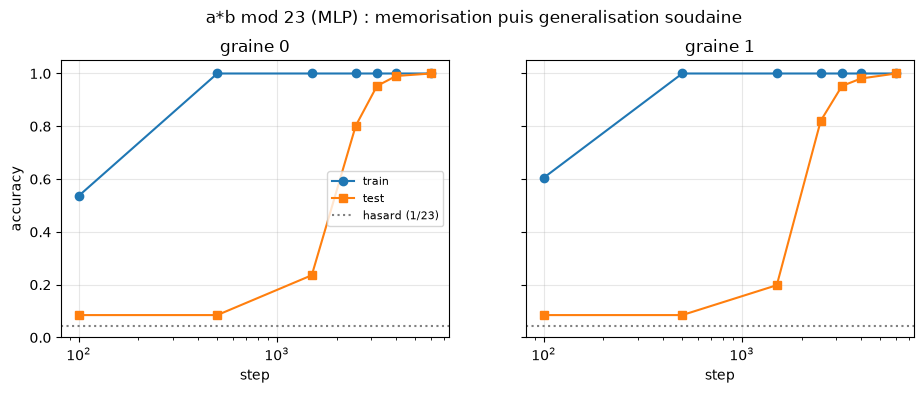

graine 0 : saut de test 0.08 -> 0.24 entre les steps 500 et 1500
graine 0 : saut de test 0.24 -> 0.80 entre les steps 1500 et 2500
graine 0 : saut de test 0.80 -> 0.95 entre les steps 2500 et 3200
graine 1 : saut de test 0.20 -> 0.82 entre les steps 1500 et 2500


In [7]:
# --- §3. Courbes train/test par graine, phases #16742 annotees ---
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, seed in zip(axes, (0, 1)):
    steps = [r["step"] for r in rows_by_seed[seed]]
    tr = [r["tr_acc"] for r in rows_by_seed[seed]]
    te = [r["te_acc"] for r in rows_by_seed[seed]]
    ax.plot(steps, tr, "o-", label="train", color="tab:blue")
    ax.plot(steps, te, "s-", label="test", color="tab:orange")
    ax.axhline(1 / P, ls=":", color="gray", label="hasard (1/23)")
    ax.set_xscale("log"); ax.set_xlabel("step")
    ax.set_title(f"graine {seed}"); ax.set_ylim(0, 1.05); ax.grid(alpha=0.3)
axes[0].set_ylabel("accuracy")
axes[0].legend(loc="center right", fontsize=8)
fig.suptitle("a*b mod 23 (MLP) : memorisation puis generalisation soudaine", y=1.02)
plt.show()

# Lecture brute par graine : ou est le saut de test ?
for seed in (0, 1):
    rows = rows_by_seed[seed]
    for a, b in zip(rows, rows[1:]):
        if b["te_acc"] - a["te_acc"] > 0.15:
            print(f"graine {seed} : saut de test {a['te_acc']:.2f} -> {b['te_acc']:.2f} "
                  f"entre les steps {a['step']} et {b['step']}")


In [8]:
# --- §3. Trajectoire d'activations : trace par checkpoint sur le lot de test fixe ---
# Les couches cachees (pre-activation) sont moissonnees par tl.trace a chaque checkpoint.
# Metrique de structure : exactitude de sondes lineaires BINAIRES qui lisent la bissection
# (a*b mod 23) < 11 depuis les activations -- sur le MEME lot fixe. Deux sondes de l'organe :
# mass-mean (sans parametre) et MM-IID (whitening classe-conditionnel, la plus sensible).

y_bin = (y_test < P // 2).long().cpu().numpy()     # labels binaires du lot fixe

def trace_at(states, X):
    """Recharge un checkpoint et trace le modele sur le lot X (aucun hook manuel)."""
    mdl = ToyMLP().to(DEV)
    mdl.load_state_dict(states)
    mdl.eval()
    with torch.no_grad():
        return tl.trace(mdl, X)

t0 = time.time()
traj, traj_iid = {}, {}   # (seed, step, adresse) -> exactitude MM / MMIID
for seed in (0, 1):
    for step in CKPTS:
        tr = trace_at(states_by_seed[seed][step], X_test)
        for addr in ("fc1", "fc2"):                # les deux couches cachees (pre-activation)
            A = tr.activations_by_address(addr)[-1].out.detach().cpu().numpy()
            theta = PRB.mass_mean_probe(A, y_bin)
            traj[(seed, step, addr)] = PRB.probe_accuracy(theta, A.mean(axis=0), A, y_bin)
            theta_iid = PRB.mm_iid_probe(A, y_bin)
            traj_iid[(seed, step, addr)] = PRB.probe_accuracy(theta_iid, A.mean(axis=0), A, y_bin)
print(f"moisson de trajectoire : {time.time() - t0:.0f} s "
      f"({2 * len(CKPTS)} traces, {2 * 2 * len(CKPTS)} x 2 sondes)")


moisson de trajectoire : 1 s (14 traces, 28 x 2 sondes)


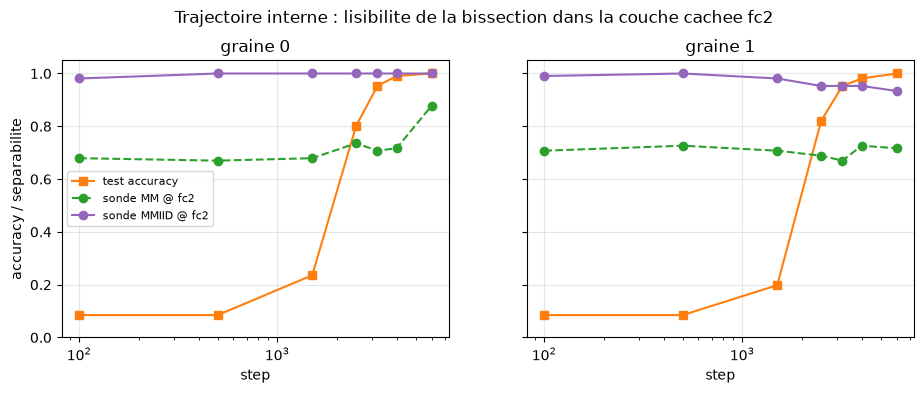

graine 0 : MM   fc2 aux steps [100, 500, 1500, 2500, 3200, 4000, 6000] -> 0.68 0.67 0.68 0.74 0.71 0.72 0.88
          MMIID fc2 -> 0.98 1.00 1.00 1.00 1.00 1.00 1.00
          test acc finale = 1.000
graine 1 : MM   fc2 aux steps [100, 500, 1500, 2500, 3200, 4000, 6000] -> 0.71 0.73 0.71 0.69 0.67 0.73 0.72
          MMIID fc2 -> 0.99 1.00 0.98 0.95 0.95 0.95 0.93
          test acc finale = 1.000


In [9]:
# --- §3. Figure : te_acc vs separabilite lineaire de la couche cachee fc2, par checkpoint ---
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, seed in zip(axes, (0, 1)):
    steps = list(CKPTS)
    te = [next(r["te_acc"] for r in rows_by_seed[seed] if r["step"] == s) for s in steps]
    s_mm = [traj[(seed, s, "fc2")] for s in steps]
    s_iid = [traj_iid[(seed, s, "fc2")] for s in steps]
    ax.plot(steps, te, "s-", color="tab:orange", label="test accuracy")
    ax.plot(steps, s_mm, "o--", color="tab:green", label="sonde MM @ fc2")
    ax.plot(steps, s_iid, "o-", color="tab:purple", label="sonde MMIID @ fc2")
    ax.set_xscale("log"); ax.set_xlabel("step")
    ax.set_title(f"graine {seed}"); ax.set_ylim(0, 1.05); ax.grid(alpha=0.3)
axes[0].set_ylabel("accuracy / separabilite")
axes[0].legend(fontsize=8)
fig.suptitle("Trajectoire interne : lisibilite de la bissection dans la couche cachee fc2", y=1.02)
plt.show()

# Verdict chiffre : trajectoires completes, par graine
for seed in (0, 1):
    mm = " ".join(f"{traj[(seed, s, 'fc2')]:.2f}" for s in CKPTS)
    iid = " ".join(f"{traj_iid[(seed, s, 'fc2')]:.2f}" for s in CKPTS)
    print(f"graine {seed} : MM   fc2 aux steps {list(CKPTS)} -> {mm}")
    print(f"          MMIID fc2 -> {iid}")
    print(f"          test acc finale = {rows_by_seed[seed][-1]['te_acc']:.3f}")


### Lecture honnête de la trajectoire

Ce que la figure montre et ce qu'elle ne peut pas montrer :

- **Ce qui est mesuré — et c'est le résultat le plus instructif du carnet** : la lisibilité
  linéaire de la bissection **précède** le grokking. La sonde MMIID lit `(a*b mod 23) < 11` dans
  `fc2` à **0.98 dès le step 100** (graine 0 : 0.98 ; graine 1 : 0.99) — bien avant que le réseau
  ne mémorise son train (train 0.54 à ce step), et des milliers de pas avant le saut de test
  (0.08 → 1.00, dont l'essentiel se joue entre les steps 1500 et 3200). L'information nécessaire
  à la bissection est *linéairement présente dès les premières centaines de pas* ; ce qui manque
  au réseau pré-grok n'est pas l'information mais son **exploitation** par la tête de lecture. Le
  réseau « sait » avant de « répondre » — la dissociation savoir/répondre de la série, ici visible
  en deux courbes.
- **Le contraste entre sondes est la moitié de la leçon** : la mass-mean (sans paramètre, lecture
  brute de la direction `mu_+ - mu_-`) reste à ~0.70 avec une montée finale sur la graine 0
  seulement (0.72 → 0.88). La MMIID (whitening classe-conditionnel) voit l'information à 1.00.
  Autrement dit : l'information est présente **dans des directions à faible variance**, que la
  lecture brute ne distingue pas — c'est précisément le régime où la sonde MM-IID est la bonne
  lecture, et la raison pour laquelle l'organe en porte trois.
- **La liaison aux phases de #16742** : la fenêtre couvre *memorization* (train à 1.0 dès le step
  500, test au hasard) puis *grokking* (saut 1500–3200). Les phases *comprehension* et
  *confusion* demandent le balayage des leviers — livrable de #16742, pas de ce carnet : nous
  démontrons **l'instrument de trajectoire**, pas le diagramme.
- **Ce que ceci n'établit pas** : aucune claim mécanistique sur l'encodage (bases de Fourier,
  circuits — chantier de Nanda et al. 2023). Deux graines établissent que l'instrument capture le
  phénomène de façon reproductible ; la claim « la lisibilité précède le grok » sur **cette**
  tâche est mesurée sur deux graines, avec le protocole multi-graines rigoureux en 17b pour
  l'étendre.


In [10]:
# --- §4. Moisson multi-couches au checkpoint final -> sondes ict/probes.py ---
# Un seul tl.trace rend TOUTES les activations retenues (adresses = noms des modules nommes).
tr_final = trace_at(states_by_seed[0][6000], X_test)

harvest = {}
for addr in ("fc1", "fc2", "head"):
    harvest[addr] = tr_final.activations_by_address(addr)[-1].out.detach().cpu().numpy()

print("moisson multi-couches :")
for addr, A in harvest.items():
    print(f"  {addr:5s} -> {A.shape}")

# Les trois sondes de l'organe, sur chaque couche moissonnee.
# Convention : train_probes rend (directions, mu_train) ; probe_accuracy(theta, mu_train, X, y).
probe_table = {}
for addr, A in harvest.items():
    directions, mu = PRB.train_probes(A, y_bin)                # MM / LR / MMIID
    probe_table[addr] = {k: PRB.probe_accuracy(v, mu, A, y_bin)
                         for k, v in directions.items()}

print("\nexactitude des sondes par couche (checkpoint grokke, graine 0) :")
print(f"{'couche':7s} {'MM':>6s} {'LR':>6s} {'MMIID':>6s}")
for addr, accs in probe_table.items():
    print(f"{addr:7s} {accs['MM']:6.3f} {accs['LR']:6.3f} {accs['MMIID']:6.3f}")


moisson multi-couches :
  fc1   -> (106, 256)
  fc2   -> (106, 256)
  head  -> (106, 23)

exactitude des sondes par couche (checkpoint grokke, graine 0) :
couche      MM     LR  MMIID
fc1      0.764  0.792  0.821
fc2      0.877  0.962  1.000
head     0.849  0.943  0.972


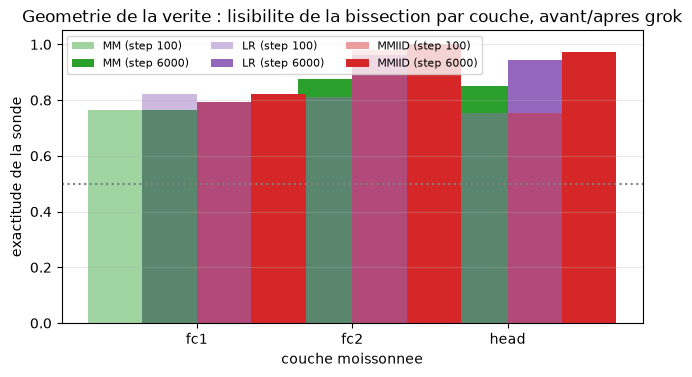

In [11]:
# --- §4 bis. La meme moisson AVANT le grok : ou l'information n'est pas encore ---
tr_early = trace_at(states_by_seed[0][100], X_test)           # checkpoint de memorisation
harvest_early = {a: tr_early.activations_by_address(a)[-1].out.detach().cpu().numpy()
                 for a in ("fc1", "fc2", "head")}

probe_table_early = {}
for addr, A in harvest_early.items():
    directions, mu = PRB.train_probes(A, y_bin)
    probe_table_early[addr] = {k: PRB.probe_accuracy(v, mu, A, y_bin)
                               for k, v in directions.items()}

# Figure : sonde par couche, avant/apres le grok
layers = ("fc1", "fc2", "head")
xpos = np.arange(len(layers))
width = 0.35
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for j, (probe, color) in enumerate((("MM", "tab:green"), ("LR", "tab:purple"), ("MMIID", "tab:red"))):
    before = [probe_table_early[a][probe] for a in layers]
    after = [probe_table[a][probe] for a in layers]
    ax.bar(xpos + (j - 1) * width - width / 2, before, width, alpha=0.45, color=color, label=f"{probe} (step 100)")
    ax.bar(xpos + (j - 1) * width + width / 2, after, width, color=color, label=f"{probe} (step 6000)")
ax.axhline(0.5, ls=":", color="gray")
ax.set_xticks(xpos, layers); ax.set_xlabel("couche moissonnee")
ax.set_ylabel("exactitude de la sonde"); ax.set_ylim(0, 1.05)
ax.set_title("Geometrie de la verite : lisibilite de la bissection par couche, avant/apres grok")
ax.legend(fontsize=8, ncol=3); ax.grid(alpha=0.3, axis="y")
plt.show()


### Lecture : le complément, pas le remplacement

La figure avant/après dit trois choses. **(1)** Au checkpoint grokké, la lisibilité monte de la
première couche cachée à la seconde — MM : 0.76 (`fc1`) → 0.88 (`fc2`), MMIID : 0.82 → 1.00 : la
bissection devient une direction de plus en plus propre au fur et à mesure que la représentation
se construit. **(2)** Aux logits (`head`), elle **plafonne, voire redescend** (MM 0.85, MMIID
0.97 < 1.00 de `fc2`) : les logits encodent les 23 classes du résidu, pas la bissection — celle-ci
n'y est qu'une lecture dérivée, moins directement alignée que dans la couche cachée où elle
émerge. Détail instructif : l'information n'est pas « max en sortie », elle est *max là où elle
est devenue linéaire*. **(3)** À cette précision d'affichage, les sondes du checkpoint 100
paraissent proches du hasard, mais ce serait une mauvaise lecture : MMIID lit déjà la bissection
à 0.98 dans `fc2` au §3. Le contraste important est donc entre la **mass-mean**, restée autour de
0.70, et la MMIID : seule la seconde exploite les directions à faible variance où réside déjà
l'information. L'absence de saut MMIID dans ce tableau ne signifie pas absence de représentation.

C'est le contrat de complémentarité en acte : la moisson TorchLens rend les matrices `X` par
couche, l'organe `ict/probes.py` les lit sans modification, et les scripts dédiés Qwen/local
(`measure_truth_geometry_rung.py` et consœurs) continuent de porter les métriques calibrées sur
les vrais modèles. La seule chose que ce carnet ajoute au dispositif existant : la même lecture
devenue possible **sur n'importe quel modèle en mémoire, en trois lignes**.


### Exercice 1 — Carte de nécessité par ablation

L'ablation du §2 porte sur un site. Étendez-la en **carte** : pour chaque couche cachée du modèle
grokké (`fc1`, `fc2`), ablatez l'activation sur tout le lot de test et mesurez la chute de
test-accuracy. Quelle couche est la plus *nécessaire* à la réponse ? Comparez au profil de
lisibilité du §4 — nécessité et lisibilité coïncent-elles ?

**Indices** : partez d'un trace frais `tl.trace(model, X_test)`, capturez l'accuracy de référence
*avant* tout `do()` (piège n°3 du §2), puis bouclez sur les adresses `"fc1"` et `"fc2"`.


In [12]:
# Exercice 1 : carte de necessite par ablation. Stub a completer.
# TODO etudiant :
#   1. Recharger le checkpoint final (states_by_seed[0][6000]) dans un ToyMLP.
#   2. tl.trace(mdl, X_test) puis accuracy de reference AVANT toute intervention.
#   3. Pour chaque adresse dans ("fc1", "fc2") :
#        h_abl = trace_frais.do(site, lambda t, *, ctx: torch.zeros_like(t),
#                               model=mdl, inputs=X_test)
#        mesurer l'accuracy de h_abl.output.
#   4. Afficher la chute d'accuracy par couche.
print("Exercice a completer : carte de necessite par ablation")
result_ex1 = None  # TODO etudiant : dict adresse -> chute d'accuracy


Exercice a completer : carte de necessite par ablation


### Exercice 2 — Patching croisé entre checkpoints : la réponse suit-elle la représentation ?

Le patching du §2 échange des activations entre *batchs*. Une variante plus intéressante pour le
grokking : échanger des activations entre **checkpoints**. Grefez l'activation `fc2` du checkpoint
grokké (step 6000) dans le run du checkpoint de mémorisation (step 100) : l'accuracy de test suit-elle
la représentation greffée (celle du réseau grokké) ou l'entrée nominale (celle du réseau
memorisateur) ?

**Indices** : deux traces frais, un pour chaque checkpoint ; le donneur fournit
`activations_by_address("fc2")[-1].out.detach()`, le receveur arme le `do()` au même site.
Attention à recharger chaque checkpoint dans sa propre instance de `ToyMLP`.


In [13]:
# Exercice 2 : patching croise entre checkpoints. Stub a completer.
# TODO etudiant :
#   1. mdl_early (step 100) et mdl_late (step 6000), chacun dans son ToyMLP.
#   2. tr_late = tl.trace(mdl_late, X_test) ; act_late = son activation fc2.
#   3. tr_early = tl.trace(mdl_early, X_test) ; armer le patch de act_late sur "fc2"
#      (lambda t, *, ctx: act_late), avec model=mdl_early, inputs=X_test.
#   4. Comparer : accuracy du early patche vs early nominal vs late nominal.
print("Exercice a completer : patching croise entre checkpoints")
result_ex2 = None  # TODO etudiant : triplet (early, early_patched, late) d'accuracies


Exercice a completer : patching croise entre checkpoints


### Exercice 3 — Anatomie de la transition : sondes sur un checkpoint du milieu

Le §4 compare step 100 et step 6000. La transition vit *entre* eux. Reprenez la moisson
multi-couches au checkpoint `2500` (ou `3200`) — pile dans la fenêtre du saut — et tracez le profil
de lisibilité par couche. Est-il déjà « grokké », encore « memorisateur », ou intermédiaire ?
Comparez aux deux tableaux du §4 pour situer le moment où la géométrie bascule.

**Indices** : `trace_at(states_by_seed[0][2500], X_test)` puis la même boucle
`train_probes` / `probe_accuracy` par adresse. Une seule ligne change par rapport au §4.


In [14]:
# Exercice 3 : sondes sur un checkpoint de milieu de transition. Stub a completer.
# TODO etudiant :
#   1. tr_mid = trace_at(states_by_seed[0][2500], X_test)   # ou 3200
#   2. Moissonner ("fc1", "fc2", "head") comme au §4.
#   3. train_probes + probe_accuracy par couche, afficher le tableau.
#   4. Situer le profil obtenu entre les tableaux step 100 et step 6000 du §4.
print("Exercice a completer : sondes sur checkpoint intermediaire")
result_ex3 = None  # TODO etudiant : dict adresse -> dict sonde -> accuracy


Exercice a completer : sondes sur checkpoint intermediaire


## §6. Conclusion

**Ce que le carnet établit.** (1) L'instrument : `tl.trace` capture graphe, activations et
interventions sur un modèle en mémoire, avec trois pièges d'API v3.x documentés et contournés
(adresses par nom de module, `Op.out` pour le tenseur, `model=`/`inputs=` explicites pour que
`do()` rejoue). (2) La trajectoire : sur `a*b mod 23`, MMIID lit la bissection presque parfaitement
dès le step 100, alors que la mass-mean reste bruitée et la test-accuracy au hasard jusqu'à la
transition ; la différence entre lectures fait apparaître une information déjà présente mais non
encore exploitée par la tête. (3) La moisson : les activations multi-couches nourrissent
`ict/probes.py` telles quelles, avant et après grok, sans aucun changement des instruments dédiés.

**Ce qu'il ne faut pas en conclure.** Aucune claim mécanistique d'encodage (bases de Fourier,
circuits), aucune claim de phase au-delà de la fenêtre observée — le diagramme de phases complet
est #16742, la démonstration grokking multi-graines rigoureuse est [17b](ICT-17b-Grokking-CompressionProgress-Python.ipynb).
TorchLens **ne remplace pas** les instruments dédiés de la série : il offre une inspection générique
avant leurs mesures spécialisées.

**Pont vers la série 2.9-ML.** Le dossier grokking existe déjà là-bas
(`2.9-Grokking-Generalisation.ipynb`, `2.9f-Grokking-Theorie-Effective-Lean.ipynb`,
formalisation `Grokking.lean`) ; ce carnet en propose le volet inspection depuis ICT-Series, sans
modifier ces séries.


## §7. Références

**Outil**

- **Taylor, J., & Kriegeskorte, N. (2023).** *TorchLens: interactive dissection of PyTorch models.*
  Scientific Reports 13:14375. doi:10.1038/s41598-023-40807-0. — L'outil de ce carnet :
  capture exhaustive forward/backward, graphe auto-rendu, interventions causales, architectures
  dynamiques/RNN/transformers. Licence **Apache-2.0**. Version épinglée **`torchlens==3.0.3`**
  (voir `requirements-torchlens.txt` ; l'API 3.x diffère des docstrings 2.x en ligne).

**Grokking**

- **Power, A., Burba, Y., Edwards, H., Babuschkin, I., & Misra, V. (2022).** *Grokking:
  Generalization Beyond Overfitting on Small Algorithmic Datasets.* ICLR 2022 workshop ;
  arXiv:2201.02177. — Papier fondateur ; la recette AdamW `weight_decay=1.0` reprise au §3.
- **Nanda, N., Chan, L., Lieberum, T., Smith, J., & Steinhardt, J. (2023).** *Progress Measures
  for Grokking via Mechanistic Interpretability.* ICLR 2023 ; arXiv:2301.05217. — Le chantier
  mécanistique (bases de Fourier) que ce carnet ne touche pas.

**Ancres internes de la série**

- **Issue #25465** — issue porteuse : contexte opérateur, contraintes de sécurité (jamais
  `tl.load()`), scripts ICT intacts, acceptance criteria.
- **Issue #16742** — diagrammes de phases du grokking (comprehension / memorization / grokking /
  confusion) : le cadre de lecture du §3.
- **Issues #16760 / #16890** — géométrie de la vérité : `ict/probes.py` et le rung Qwen,
  consommateurs de la moisson du §4.
- **Carnet [ICT-17b](ICT-17b-Grokking-CompressionProgress-Python.ipynb)** — la démonstration
  grokking rigoureuse multi-graines dont le §3 est le volet inspection.


In [15]:
# --- Recapitulatif d'execution : les valeurs mesurles de ce carnet ---
print("=== Recapitulatif ICT-17c ===")
print(f"torchlens {tl.__version__} | torch {torch.__version__} | device {DEV}")
print(f"§1  : graphe forward rendu -> {GRAPH_PATH} ({os.path.getsize(GRAPH_PATH)} octets)")
print(f"§2  : patching croise -> sortie == out(B) au sens allclose(1e-6) : OK")
for seed in (0, 1):
    last = rows_by_seed[seed][-1]
    print(f"§3  : graine {seed} | grok : test {next(r['te_acc'] for r in rows_by_seed[seed] if r['step']==CKPTS[0]):.2f} "
          f"-> {last['te_acc']:.2f} | sonde fc2 finale {traj[(seed, CKPTS[-1], 'fc2')]:.2f}")
print(f"§4  : sondes @6000 fc2 -> MM {probe_table['fc2']['MM']:.2f}, LR {probe_table['fc2']['LR']:.2f}, "
      f"MMIID {probe_table['fc2']['MMIID']:.2f} (vs @100 MM {probe_table_early['fc2']['MM']:.2f})")
print("Securite : aucun appel tl.load() dans ce carnet (tl.trace uniquement, modele en memoire).")


=== Recapitulatif ICT-17c ===
torchlens 3.0.3 | torch 2.14.0+cu126 | device cuda
§1  : graphe forward rendu -> assets/ict17c_graph_forward.png (36533 octets)
§2  : patching croise -> sortie == out(B) au sens allclose(1e-6) : OK
§3  : graine 0 | grok : test 0.08 -> 1.00 | sonde fc2 finale 0.88
§3  : graine 1 | grok : test 0.08 -> 1.00 | sonde fc2 finale 0.72
§4  : sondes @6000 fc2 -> MM 0.88, LR 0.96, MMIID 1.00 (vs @100 MM 0.68)
Securite : aucun appel tl.load() dans ce carnet (tl.trace uniquement, modele en memoire).
